In [1]:
import json
import subprocess
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from collect import smoke_check
from IPython.display import display, Image

BASE = Path.cwd()
def read_json(name):
    return json.loads((BASE / "results.json").read_text(encoding="utf-8"))[name]

# True повторно выполнит сбор отдельными процессами, что совместимо с Jupyter.
RUN_COLLECTION = False
if RUN_COLLECTION:
    for mode in ["browser", "light"]:
        subprocess.run([sys.executable, str(BASE / "collect.py"), mode], check=True)

# Часть 1. Сбор данных с динамических страниц

Соберём товары через Playwright и прямые HTTP-запросы. В наборе 147 товаров ScrapingCourse и 60 ноутбуков Web Scraper. Код сбора находится в collect.py и webscraper_source.py, диагностика - в diagnose.py.

### 1.1. Диагностика источников

ScrapingCourse возвращает первые 12 карточек в HTML. Кнопка Load more вызывает GET /ajax/products?offset=10. Без JavaScript число карточек после клика не меняется, с JavaScript становится 24.

В Web Scraper карточки создаются JavaScript. Кнопка More добавляет по 6 товаров. Все 117 ноутбуков уже находятся в JSON атрибута data-items; для работы выбираем первые 60.

In [2]:
diagnosis = read_json("artifacts/diagnosis.json")
display(pd.DataFrame([
    ["Размер исходного HTML, байт", diagnosis["requests_html_bytes"]],
    ["Карточек в requests", diagnosis["requests_cards"]],
    ["Карточек после одного клика с JS", diagnosis["after_one_click"]],
    ["Карточек после клика без JS", diagnosis["no_js_cards_after_click"]],
    ["Текст нового товара в исходном HTML", diagnosis["target_in_initial_html"]],
    ["Формат AJAX-ответа", diagnosis["xhr"]["content_type"]],
], columns=["Проверка", "Результат"]))
print("Запрос:", diagnosis["xhr"]["method"], diagnosis["xhr"]["url"])
web_diagnosis = read_json("artifacts/webscraper_diagnosis.json")
display(pd.Series(web_diagnosis, name="Диагностика Web Scraper").to_frame())

,Проверка,Результат
0,"Размер исходного HTML, байт",15572
1,Карточек в requests,12
2,Карточек после одного клика с JS,24
3,Карточек после клика без JS,12
4,Текст нового товара в исходном HTML,False
5,Формат AJAX-ответа,text/html; charset=utf-8


Запрос: GET https://www.scrapingcourse.com/ajax/products?offset=10


,Диагностика Web Scraper
url,https://webscraper.io/test-sites/e-commerce/mo...
robots_allowed,True
requests_html_bytes,54281
requests_cards,0
inline_json,True
inline_location,.ecomerce-items[data-items]
available_items,117
unique_items,117
no_js_cards_before,0
no_js_cards_after_click,0


### 1.2. Сбор через браузер

Создаются browser, context и page. Заданы User-Agent, окно 1280 × 900, локаль en-US, таймауты 15 и 30 секунд. Ресурсы закрываются в finally.

После клика ожидаем AJAX-ответ и изменение DOM. Пауза между итерациями - 0,7 секунды. Ограничения: 30 итераций, 240 товаров основного каталога и 60 ноутбуков, остановка после двух итераций без прироста. Поля извлекаются через locator.evaluate_all.

| Локатор | Смена CSS-класса | Новый div | Перевод кнопки |
|---|---|---|---|
| get_by_test_id('load-more-btn') | Не влияет | Не влияет | Не влияет |
| #product-grid .product-item | Может сломать | Не влияет | Не влияет |
| a[href] внутри карточки | Не влияет | Не влияет | Не влияет |
| [itemtype='https://schema.org/Product'] | Устойчив при сохранении контейнера | Не влияет | Не влияет |
| a.ecomerce-items-scroll-more | Может сломать | Не влияет | Не влияет |

При смене класса карточки можно искать ссылки #product-grid a[href*='/ecommerce/product/']. После изменения сайта проверяются названия и цены.

In [3]:
browser = pd.read_csv(BASE / "data_browser.csv")
light = pd.read_csv(BASE / "data_light.csv")
browser_metrics = read_json("browser_metrics.json")
light_metrics = read_json("light_metrics.json")
display(browser.head(10))
print("Записей:", len(browser), "Кликов:", browser_metrics["clicks"])
print("Сырых карточек:", browser_metrics["raw_cards"], "Повторов удалено:", browser_metrics["removed_duplicates"])
print("Остановка:", browser_metrics["stop_reason"])
display(pd.Series(browser_metrics["source_counts"], name="Товаров по источникам").to_frame())

,product_id,name,price,currency,product_url
0,100,Dell Latitude 5480,1110.14,USD,https://webscraper.io/test-sites/e-commerce/mo...
1,31,Packard 255 G2,416.99,USD,https://webscraper.io/test-sites/e-commerce/mo...
2,32,Aspire E1-510,306.99,USD,https://webscraper.io/test-sites/e-commerce/mo...
3,34,ProBook,739.99,USD,https://webscraper.io/test-sites/e-commerce/mo...
4,36,Aspire E1-572G,581.99,USD,https://webscraper.io/test-sites/e-commerce/mo...
5,37,ThinkPad Yoga,1033.99,USD,https://webscraper.io/test-sites/e-commerce/mo...
6,38,Pavilion,609.99,USD,https://webscraper.io/test-sites/e-commerce/mo...
7,39,Inspiron 15,745.99,USD,https://webscraper.io/test-sites/e-commerce/mo...
8,4-zip-light-jacket,Olivia 1/4 Zip Light Jacket,77.00,USD,https://scrapingcourse.com/ecommerce/product/o...
9,42,HP 250 G3,520.99,USD,https://webscraper.io/test-sites/e-commerce/mo...


Записей: 207 Кликов: 24
Сырых карточек: 235 Повторов удалено: 28
Остановка: sources_finished


,Товаров по источникам
scrapingcourse,147
webscraper,60


### 1.3. Сбор без браузера

Для ScrapingCourse используем requests.Session и AJAX с offset. Ответ 204 или пустая порция завершает сбор. Повторы карточек удаляются по product_id.

Для Web Scraper достаточно одного запроса и разбора data-items через json.loads. Оба результата имеют поля product_id, name, price, currency и product_url.

In [4]:
pd.testing.assert_frame_equal(browser, light, check_dtype=False)
print("Полные наборы совпали:", len(browser), "строк")
display(browser.dtypes.rename("Тип").to_frame())
quality = smoke_check(browser)
display(pd.Series(quality, name="Качество").to_frame())

Полные наборы совпали: 207 строк


,Тип
product_id,str
name,str
price,float64
currency,str
product_url,str


Smoke-check: обязательные поля заполнены


,Качество
records,207
empty_required_fraction,0.0
empty_by_field,"{'product_id': 0, 'name': 0, 'price': 0, 'prod..."
duplicates,0
nonpositive_prices,0
price_type,float64
warning,False


### 1.4. Проверки и обработка сбоя

Проверяем заполненность, дубликаты и цены. Smoke-check предупреждает, если обязательные поля пусты более чем у 5% строк. Проверим его на отдельной копии с пропусками.

В diagnose.py ожидается заведомо отсутствующий элемент. При TimeoutError сохраняются HTML и снимок в artifacts, после чего обработка продолжается. Ошибочный запуск сборщика завершается ненулевым кодом.

In [5]:
damaged = browser.copy()
from math import ceil
missing_count = ceil(len(damaged) * 0.06)
damaged.loc[:missing_count-1, "name"] = ""
demo_quality = smoke_check(damaged)
assert demo_quality["warning"]
print("Доля строк с пропусками в тестовой копии:", round(demo_quality["empty_required_fraction"] * 100, 2), "%")
timeout_demo = read_json("artifacts/timeout_demo.json")
print("Ожидаемый таймаут перехвачен:", timeout_demo["expected_timeout"])
print("После него доступны карточки:", timeout_demo["continued_records"])

ПРЕДУПРЕЖДЕНИЕ: слишком много пустых полей
Доля строк с пропусками в тестовой копии: 6.28 %
Ожидаемый таймаут перехвачен: True
После него доступны карточки: 24


### 1.5. Журнал и анализ цен

В collection_log.csv сохраняются итерация, число карточек, прирост, длительность, время UTC и URL. Поле run различает запуски.

,method,iteration,items,unique_items,growth,seconds,status
62,browser_main,0,12,12,12,6.493200,200
63,browser_main,1,24,22,10,1.027100,200
64,browser_main,2,36,32,10,1.036500,200
65,browser_main,3,48,42,10,1.121000,200
66,browser_main,4,60,52,10,1.066300,200
67,browser_main,5,72,62,10,1.001700,200
68,browser_main,6,84,72,10,1.119400,200
69,browser_main,7,96,82,10,1.026800,200
70,browser_main,8,108,92,10,1.241300,200
71,browser_main,9,120,102,10,1.270100,200


,price
count,207.000000
mean,198.579179
std,276.733989
min,18.000000
25%,33.250000
50%,54.000000
75%,376.320000
max,1110.140000


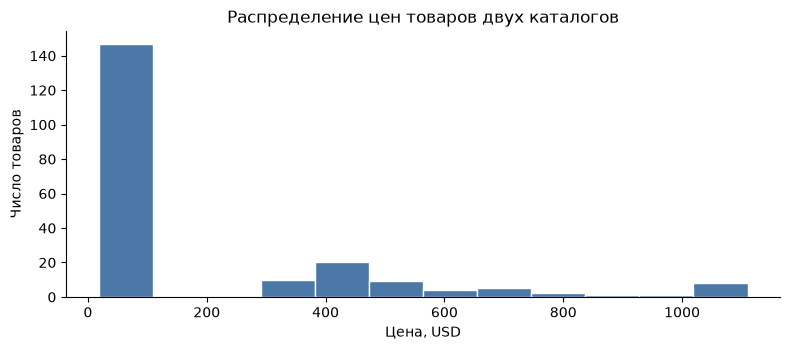

In [6]:
log = pd.read_csv(BASE / "collection_log.csv")
source_runs = [item["started_at"] for item in browser_metrics["sources"].values()]
full_browser_log = log[log["method"].isin(["browser_main", "browser_webscraper"]) & log["run"].isin(source_runs)]
display(full_browser_log[["method", "iteration", "items", "unique_items", "growth", "seconds", "status"]])
display(browser["price"].describe().to_frame())
plt.rcParams["font.family"] = "DejaVu Sans"
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(browser["price"], bins=12, color="#4c78a8", edgecolor="white")
ax.set(xlabel="Цена, USD", ylabel="Число товаров", title="Распределение цен товаров двух каталогов")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### 1.6. Сравнение способов

Контрольные замеры выполнены на одинаковых 22 товарах. Для Python приведены медианы трёх прогонов, для n8n - сохранённый успешный запуск. Трафик измерен по телам ответов. Память n8n - сумма максимумов контейнера и рендерера.

Отдельно сравним загрузку со всеми ресурсами и с блокировкой изображений, шрифтов и медиа.

In [7]:
benchmark = read_json("benchmark_metrics.json")
nocode_metrics = read_json("nocode/execution_summary.json")
comparison = pd.DataFrame(read_json("comparison"))
display(comparison)
display(pd.DataFrame([
    {"Режим": "Все ресурсы", "Время, с": benchmark["baseline"]["seconds"], "Трафик, МБ": benchmark["baseline"]["traffic_mb"]},
    {"Режим": "Без изображений, шрифтов и медиа", "Время, с": benchmark["browser"]["seconds"], "Трафик, МБ": benchmark["browser"]["traffic_mb"]},
]))
print("Экономия времени, %:", round(benchmark["time_saved_percent"], 2))
print("Экономия трафика, %:", round(benchmark["traffic_saved_percent"], 2))
extraction = browser_metrics["extraction"]
print("Массовое извлечение, с:", round(extraction["bulk_seconds"], 4))
print("Поэлементное извлечение, с:", round(extraction["individual_seconds"], 4))
print("Ускорение извлечения, раз:", round(extraction["speedup"], 1))

,Метрика,Playwright,AJAX requests,n8n
0,Записей в сравнении,22,22,22
1,"Время прогона, с",2.9429,1.6528,3.385
2,Сетевых запросов,14,2,15
3,"Полученные тела ответов, МБ",1.067404,0.026241,1.091501
4,"Пиковая память, МБ",497.099,112.603,1570.055
5,Секунд на запись,0.1338,0.0751,0.1539
6,"Устойчивость к редизайну, 1–5",3,4,3
7,Воспроизводимость,Python + requirements,Python + requirements,Экспорт + локальный API


,Режим,"Время, с","Трафик, МБ"
0,Все ресурсы,4.4178,4.040991
1,"Без изображений, шрифтов и медиа",2.9429,1.067404


Экономия времени, %: 33.39
Экономия трафика, %: 73.59
Массовое извлечение, с: 0.0118
Поэлементное извлечение, с: 4.7922
Ускорение извлечения, раз: 406.0


# Часть 2. Сбор данных в n8n

Сценарий отправляет запрос локальному render_api.py. Рендерер открывает страницу с JavaScript, ждёт карточки и нажимает Load more один раз. Узлы n8n извлекают поля, разворачивают массив, приводят цену к числу, удаляют дубликаты и сохраняют CSV.

Получены 22 уникальных товара из 24 карточек. Один запуск использует один JS-рендеринг; 100 запусков - 100 рендерингов. Ошибки сохраняются отдельной веткой. Расписание на 09:00 по Перми выключено до публикации workflow.

In [8]:
nocode = pd.read_csv(BASE / "nocode" / "nocode_result.csv").sort_values("product_id").reset_index(drop=True)
subset = browser[browser["product_id"].isin(nocode["product_id"])].reset_index(drop=True)
pd.testing.assert_frame_equal(nocode, subset, check_dtype=False)
print("Все три способа совпали на", len(nocode), "товарах")
display(nocode.head())

Все три способа совпали на 22 товарах


,product_id,name,price,currency,product_url
0,abominable-hoodie,Abominable Hoodie,69.0,USD,https://scrapingcourse.com/ecommerce/product/a...
1,ajax-full-zip-sweatshirt,Ajax Full-Zip Sweatshirt,69.0,USD,https://scrapingcourse.com/ecommerce/product/a...
2,beaumont-summit-kit,Beaumont Summit Kit,42.0,USD,https://scrapingcourse.com/ecommerce/product/b...
3,bruno-compete-hoodie,Bruno Compete Hoodie,63.0,USD,https://scrapingcourse.com/ecommerce/product/b...
4,chaz-kangeroo-hoodie,Chaz Kangeroo Hoodie,52.0,USD,https://scrapingcourse.com/ecommerce/product/c...


### 2.1. Схема и успешный запуск

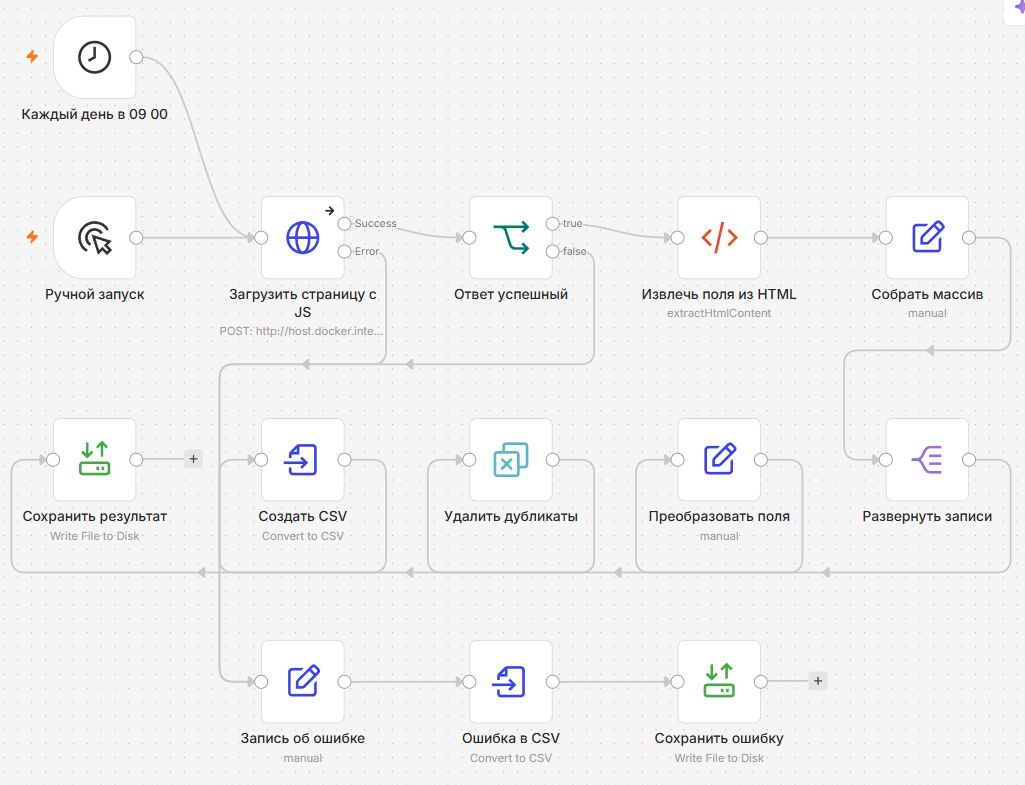

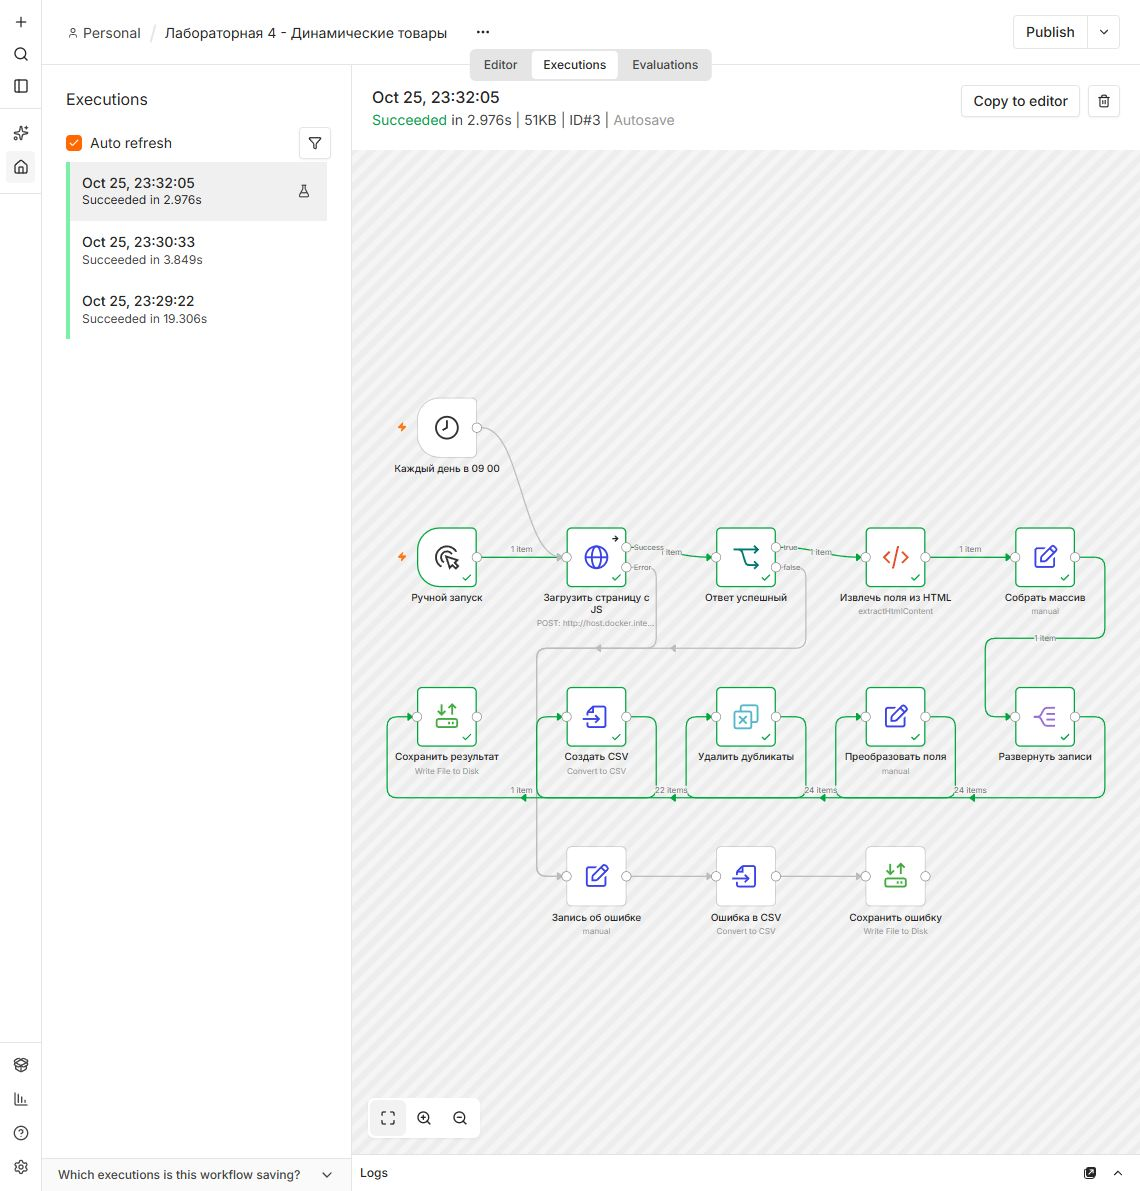

In [9]:
for name in ["screenshot_workflow.png", "screenshot_success.png"]:
    display(Image(filename=str(BASE / "nocode" / name), width=1000))

# Итоговый вывод

Получено 207 уникальных товаров при 24 нажатиях кнопок. Наборы Playwright и requests совпали. Пустых обязательных полей и дубликатов нет. Выборка n8n совпала с Python по 22 товарам.

Playwright удобен для разового исследования страницы. Для ежедневного сбора 10 000 записей подходит разрешённый API или AJAX. n8n удобен для небольшого сценария по расписанию. Для сайта с антибот-защитой нужен официальный доступ к данным.

Использованы учебные каталоги и паузы между запросами.

### Источники
- [ScrapingCourse](https://www.scrapingcourse.com/button-click)
- [Web Scraper](https://webscraper.io/test-sites/e-commerce/more/computers/laptops)
- [Playwright: локаторы](https://playwright.dev/python/docs/locators)
- [n8n: HTML](https://docs.n8n.io/integrations/builtin/core-nodes/n8n-nodes-base.html/)